# Object-Oriented Design for Implementation

## Utilities

In [97]:
import time
import numpy as np
import torch
from torch import nn
import d2l

In [24]:
help(d2l)

Help on module d2l.torch in d2l:

NAME
    d2l.torch

CLASSES
    builtins.object
        Accumulator
        Animator
        Benchmark
        HyperParameters
            DataModule
                FashionMNIST
                MTFraEng
                SyntheticRegressionData
                TimeMachine
            HPOScheduler
                BasicScheduler
                SuccessiveHalvingScheduler
            HPOSearcher
                RandomSearcher
            HPOTuner
            Module(torch.nn.modules.module.Module, HyperParameters)
                Classifier
                    EncoderDecoder
                        Seq2Seq
                    LeNet
                    RNNLMScratch
                        RNNLM
                    SoftmaxRegression
                LinearRegression
                LinearRegressionScratch
                MultiHeadAttention
                RNN
                    GRU
                RNNScratch
            ProgressBoard
            SGD
         

In [5]:
from d2l import torch as d2l

In [6]:
def add_to_class(Class):  #@save
    """Register functions as methods in created class."""
    def wrapper(obj):
        setattr(Class, obj.__name__, obj)
    return wrapper

In [7]:
class A:
    def __init__(self):
        self.b = 1

a = A()

In [ ]:
@add_to_class(A)
def do(self):
    print('Class attribute "b" is', self.b)
    
a.do()

Class attribute "b" is 1


In [11]:
@add_to_class(A)
def done(self):
    print(f"Additive class attribute of 'b' is", self.b + 1)

a.done()

Additive class attribute of 'b' is 2


The second one is a utility class that saves all arguments in a class’s `__init__` method as class attributes. This allows us to extend constructor call signatures implicitly without additional code.

In [102]:
class HyperParameters:  #@save
    """The base class of hyperparameters."""
    def save_hyperparameters(self, ignore=[]):
        raise NotImplemented
    
print(HyperParameters())

In [46]:
# Call the fully implemented HyperParameters class saved in d2l
class B(d2l.HyperParameters):
    def __init__(self, a, b, c):
        self.save_hyperparameters(ignore=['c'])
        print('self.a =', self.a, 'self.b =', self.b)
        print('There is no self.c =', not hasattr(self, 'c'))

b = B(a=2, b=5, c=7)

self.a = 2 self.b = 5
There is no self.c = True


In [98]:
# Not part of the codebase
class C:
    def __init__(self, a, b, c):
        self.a = a 
        self.b = b 
        self.c = c 
        
        print('self.a =', self.a, 'self.b =', self.b)
        print('There is no self.c =', not hasattr(self, 'c'))

c = C(a=2, b=6, c=7)

self.a = 2 self.b = 6
There is no self.c = False


In [19]:
class ProgressBoard(d2l.HyperParameters):  #@save
    """The board that plots data points in animation."""
    def __init__(self, xlabel=None, ylabel=None, xlim=None,
                 ylim=None, xscale='linear', yscale='linear',
                 ls=['-', '--', '-.', ':'], colors=['C0', 'C1', 'C2', 'C3'],
                 fig=None, axes=None, figsize=(5.5, 3.5), display=True):
        self.save_hyperparameters()

    def draw(self, x, y, label, every_n=1):
        raise NotImplemented

In the following example, we draw `sin` and `cos` with a different smoothness.

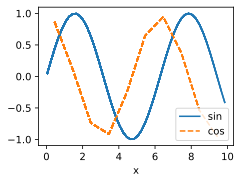

In [21]:
board = d2l.ProgressBoard('x')
for x in np.arange(0, 10, 0.1):
    board.draw(x, np.sin(x), 'sin', every_n=2)
    board.draw(x, np.cos(x), 'cos', every_n=10)

## Models

The Module class is the base class of all models we will implement. At the very least we need three methods. The first, `__init__`, stores the learnable parameters, the `training_step` method accepts a data batch to return the loss value, and finally, `configure_optimizers` returns the optimization method, or a list of them, that is used to update the learnable parameters. Optionally we can define `validation_step` to report the evaluation measures. Sometimes we put the code for computing the output into a separate `forward` method to make it more reusable.

In [22]:
class Module(nn.Module, d2l.HyperParameters):   #@save
    """The base class of models."""
    def __init__(self, plot_train_per_epoch=2, plot_valid_per_epoch=1):
        super().__init__()
        self.save_hyperparameters()
        self.board = ProgressBoard()
        
    def loss(self, y_hat, y):
        raise NotImplementedError
    
    def forward(self, X):
        assert hasattr(self, 'net'), 'Neural network is defined'
        return self.net(X)
    
    def plot(self, key, value, train):
        """Plot a point in animation"""
        assert hasattr(self, 'trainer'), 'Trainer is not inited'
        self.board.xlabel = 'epoch'
        if train:
            x = self.trainer.train_batch_idx / \
                self.trainer.num_train_batches
            n = self.trainer.num_train_batches / \
                self.plot_train_per_epoch
        else:
            x = self.trainer.epoch + 1
            n = self.trainer.num_val_batches / \
                self.plot_valid_per_epoch
        self.board.draw(x, value.to(d2l.cpu()).detach().numpy(),
                        ('train_' if train else 'val_') + key,
                        every_n=int(n))
    
    def training_step(self, batch):
        l = self.loss(self(*batch[:-1]), batch[-1])
        self.plot('loss', l, train=True)
        return l
    
    def validation_step(self, batch):
        l = self.loss(self(*batch[:-1]), batch[-1])
        self.plot('loss', l, train=False)
        
    def configure_optimizers(self):
        raise NotImplementedError

You may notice that Module is a subclass of `nn.Module`, the base class of neural networks in PyTorch. It provides convenient features for handling neural networks. For example, if we define a forward method, such as `forward(self, X)`, then for an instance a we can invoke this method by `a(X)`. This works since it calls the forward method in the built-in `__call__` method. 

## Data

The DataModule class is the base class for data. Quite frequently the `__init__` method is used to prepare the data. This includes downloading and preprocessing if needed. The `train_dataloader` returns the data loader for the training dataset. A data loader is a (Python) generator that yields a data batch each time it is used. This batch is then fed into the `training_step` method of Module to compute the loss. There is an optional `val_dataloader` to return the validation dataset loader. It behaves in the same manner, except that it yields data batches for the validation_step method in Module.

In [35]:
class DataModule(d2l.HyperParameters): #@save
    """The base class of data"""
    def __init__(self, root='../data', num_workers=4):
        self.save_hyperparameters()
    
    def get_dataloader(self, train):
        raise NotImplementedError
    
    def train_dataloader(self):
        return self.get_dataloader(train=True)
    
    def val_dataloader(self):
        return self.get_dataloader(train=False)

## Training

The `Trainer` class trains the learnable parameters in the Module class with data specified in `DataModule`. The key method is `fit`, which accepts two arguments: `model`, an instance of `Module`, and `data`, an instance of `DataModule`. It then iterates over the entire dataset `max_epochs` times to train the model.

In [36]:
class Trainer(d2l.HyperParameters): #@save
    """The base class for training models with data"""
    def __init__(self, max_epochs, num_gpus=0, gradient_clip_val=0):
        self.save_hyperparameters()
        assert num_gpus == 0, 'No GPU support yet'
        
    def prepare_data(self, data):
        self.train_dataloader = data.train_dataloader()
        self.val_dataloader = data.val_dataloader()
        self.num_train_batches = len(self.train_dataloader)
        self.num_val_batches = (len(self.val_dataloader)
                                if self.val_dataloader is not None else 0)
        
    def prepare_model(self, model):
        model.trainer = self
        model.board.xlim = [0, self.max_epochs]
        self.model = model
        
    def fit(self, model, data):
        self.prepare_data(data)
        self.prepare_model(model)
        self.optim = model.configure_optimizers()
        self.epoch = 0
        self.train_batch_idx = 0
        self.val_batch_idx = 0
        for self.epoch in range(self.max_epochs):
            self.fit_epoch()
    
    def fit_epoch(self):
        raise NotImplementedError

## Summary

To highlight the `object-oriented design` for our future deep learning implementation, the above `classes` simply show how their objects store data and interact with each other. We will keep enriching implementations of these classes, such as via `@add_to_class`. 

Moreover, these fully implemented classes are saved in the `D2L` library, a lightweight toolkit that makes structured modeling for deep learning easy. In particular, it facilitates reusing many components between projects without changing much at all. For instance, we can replace just the `optimizer`, just the `model`, just the `dataset`, etc.; this degree of `modularity` pays dividends throughout the book in terms of conciseness and simplicity (this is why we added it) and it can do the same for your own projects.

```python
def fit(self, model, data):
    """The core training loop."""
    self.prepare_data(data)
    self.model = model
    self.optim = model.configure_optimizers()
    
    # Initialize counters for tracking progress
    self.epoch = 0
    self.train_batch_idx = 0
    self.val_batch_idx = 0
    
    for self.epoch in range(self.max_epochs):
        self.fit_epoch()
        
def fit_epoch(self):
    """Run one full epoch of training and validation."""
    # Training Phase
    self.model.train()
    for batch in self.train_dataloader:
        # Forward pass + loss calculation + backpropagation
        loss = self.model.training_step(batch)
        loss.backward()
        
        # Gradient clipping if specified
        if self.gradient_clip_val > 0:
            self.clip_gradients(self.gradient_clip_val)
            
        self.optim.step()
        self.optim.zero_grad()
        self.train_batch_idx += 1
    
    # Validation Phase (if validation data exists)
    if self.val_dataloader is not None:
        self.model.eval()
        with torch.no_grad():  # Disable gradient computation for efficiency
            for batch in self.val_dataloader:
                self.model.validation_step(batch)
                self.val_batch_idx += 1

def clip_gradients(self, clip_val):
    """Clip gradients to prevent explosion."""
    params = [p for p in self.model.parameters() if p.requires_grad]
    norm = torch.sqrt(sum(torch.sum(p.grad ** 2) for p in params))
    if norm > clip_val:
        for p in params:
            p.grad[:] *= clip_val / norm
```

**Key Components Explained:**

1.  **`prepare_data(data)`:** Called once to set up data loaders from the `DataModule`.

2.  **Optimizer Setup:** `model.configure_optimizers()` must return a configured optimizer.

3.  **Training Loop:**
    *   `model.train()`: Sets model to training mode (enables dropout, batch norm)
    *   `training_step(batch)`: Computes loss for one batch
    *   `loss.backward()`: Computes gradients
    *   `clip_gradients()`: Prevents exploding gradients (if value > 0)
    *   `optim.step()`: Updates model parameters
    *   `optim.zero_grad()`: Clears old gradients

4.  **Validation Loop:**
    *   `model.eval()`: Sets model to evaluation mode
    *   `torch.no_grad()`: Disables gradient computation for efficiency
    *   `validation_step(batch)`: Computes validation metrics (doesn't return loss for backprop)

**This implementation follows the established patterns:**
- Uses the model's `training_step` and `validation_step` methods
- Respects the data loader interface from `DataModule`
- Handles gradient clipping as specified in the constructor
- Maintains batch indices for progress tracking and plotting

# Synthetic Regression Data

Machine learning is all about `extracting information` from `data`. So you might wonder, what could we possibly learn from `synthetic data`? While we might not care intrinsically about the patterns that we ourselves baked into an `artificial data` generating model, such datasets are nevertheless useful for `didactic` purposes, helping us to evaluate the properties of our learning algorithms and to confirm that our implementations work as expected. For example, if we create data for which the correct parameters are known a priori, then we can check that our model can in fact recover them.

In [50]:
%matplotlib inline
import random
import torch
from d2l import torch as d2l

**For this example, we will work in low dimension for succinctness.** The following code snippet generates `1000` examples with `2-dimensional features` drawn from a standard normal distribution. The resulting design matrix $\mathbf{X}$ belongs to $\mathbb{R}^{1000 \times 2}$. We generate each label by applying a ground truth linear function, corrupting them via additive noise $\epsilon$, drawn independently and identically for each example:  

$$\mathbf{y} = \mathbf{X}\mathbf{w} + b + \epsilon. \tag{3.3.1}$$

For convenience, we assume that $\epsilon$ is drawn from a normal distribution with mean $\mu = 0$ and standard deviation $\sigma = 0.01$.  

Note that for object-oriented design, we add the code to the `__init__` method of a subclass of `d2l.DataModule`. It is good practice to allow the setting of any additional hyperparameters. We accomplish this with `save_hyperparameters()`. The `batch_size` will be determined later.

In [93]:
class SyntheticRegressionData(d2l.DataModule):
    """Synthetic data for linear regression"""
    def __init__(self, w, b, noise=0.01, num_train=1000, num_val=1000, batch_size=32):
        super().__init__()
        self.save_hyperparameters()
        n = num_train + num_val
        self.X = torch.randn(n, len(w))
        noise = torch.randn(n, 1) * noise
        self.y = torch.matmul(self.X, w.reshape(-1, 1)) + b + noise

**Below, we set the true parameters to $\mathbf{w} = [2, -3.4]^\top$ and $b = 4.2$. Later, we can check our estimated parameters against these ground truth values.**

In [94]:
data = SyntheticRegressionData(w=torch.tensor([2, -3.4]), b=4.2)

**Each row in `features` consists of a vector in $\mathbb{R}^2$, and each row in `labels` is a scalar. Let’s have a look at the first entry.**

In [95]:
print('features:', data.X[0], '\nlabel:', data.y[0])

features: tensor([-1.0757, -0.6222]) 
label: tensor([4.1779])


In [96]:
data.X.shape, data.y.shape

(torch.Size([2000, 2]), torch.Size([2000, 1]))

## Reading the Dataset

In [104]:
import random

@add_to_class(SyntheticRegressionData)
def get_dataloader(self, train):
    if train:
        indices = list(range(0, self.num_train))
        # The examples are read in random order
        random.shuffle(indices)
    else:
        indices = list(range(self.num_train, self.num_train+self.num_val))
    
    for i in range(0, len(indices), self.batch_size):
        batch_indices = torch.tensor(indices[i: i+self.batch_size])
        yield self.X[batch_indices], self.y[batch_indices]
                

To build some intuition, let’s inspect the first minibatch of data. Each minibatch of features provides us with both its size and the dimensionality of input features. Likewise, our minibatch of labels will have a matching shape given by `batch_size`.

In [112]:
X, y = next(iter(data.train_dataloader()))
print('X shape:', X.shape, '\ny shape:', y.shape)

X shape: torch.Size([32, 2]) 
y shape: torch.Size([32, 1])


In [115]:
len(data.train_dataloader())

32

Throughout the iteration we obtain distinct minibatches until the entire dataset has been exhausted (try this). While the iteration implemented above is good for didactic purposes, it is ineﬃcient in ways that might get us into trouble with real problems. For example, it requires that we load all the data in memory and that we perform lots of random memory access. The built-in iterators implemented in a deep learning framework are considerably more eﬃcient and they can deal with sources such as data stored in files, data received via a stream, and data generated or processed on the fly. Next let’s try to implement the same method using built-in iterators.

## Concise Implementation of the Data Loader

Rather than writing our own iterator, we can call the existing API in a framework to load data. As before, we need a dataset with features `X` and labels `y`. Beyond that, we set `batch_size` in the built-in data loader and let it take care of shuﬄing examples eﬃciently.

In [110]:
@add_to_class(DataModule) #@save
def get_tensorloader(self, tensors, train, indices=slice(0, None)):
    tensors = tuple(a[indices] for a in tensors)
    dataset = torch.utils.data.TensorDataset(*tensors)
    return torch.utils.Dataloader(dataset, self.batch_size,
                                  shuffle=train)
    

@add_to_class(SyntheticRegressionData)
def get_dataloader(self, train):
    i = slice(0, self.num_train) if train else slice(self.num_train, None)
    return self.get_tensorloader((self.X, self.y), train, i)

The new data loader behaves just like the previous one, except that it is more eﬃcient and has some added functionality.

In [111]:
X, y = next(iter(data.train_dataloader()))
print('X shape:', X.shape, '\ny shape:', y.shape)

X shape: torch.Size([32, 2]) 
y shape: torch.Size([32, 1])


For instance, the data loader provided by the framework API supports the built-in `__len__` method, so we can query its length, i.e., the number of batches.

In [116]:
len(data.train_dataloader())

32

## Summary

`Data loaders` are a convenient way of abstracting out the process of loading and manipulating data. This way the same machine learning algorithm is capable of processing many different types and sources of data without the need for modification. 

One of the nice things about data loaders is that they can be composed. For instance, we might be loading images and then have a postprocessing filter that crops them or modifies them in other ways. As such, `data loaders` can be used to describe an entire data processing pipeline.

As for the model itself, the two-dimensional linear model is about the simplest we might encounter. It lets us test out the accuracy of regression models without worrying about having insuﬃcient amounts of data or an underdetermined system of equations.

In [117]:
1e-3

0.001